# Week 11: Geocoding with OpenStreetMap

**Geocoding** means turning a description of a place ("Pratt Institute, Brooklyn" or "30 Lincoln Center Plaza") into coordinates: a **latitude** and a **longitude**. Once we have coordinates, we can put the place on a map, like the ones in Week 10.

[OpenStreetMap](https://www.openstreetmap.org) (OSM) is a free, editable map of the world. Its geocoding service is called **Nominatim**, and it's an API like the Met API from Part 10: we send a request to a web address with some parameters, and it sends back JSON.

**Rules for using it.** Nominatim is run by volunteers on a few servers, so its [usage policy](https://operations.osmfoundation.org/policies/nominatim/) matters:

* **No more than one request per second.** We'll use `time.sleep(1)`.
* **Identify your program** with a `User-Agent` header, as we did when scraping. Requests without one are blocked.
* **Don't geocode thousands of places this way.** Save (cache) the results, and don't ask for the same place twice.
* The data is © OpenStreetMap contributors. If you publish a map that uses it, say so.

In [11]:
import json
import time

import pandas as pd
import plotly.express as px
import requests

## 1. One request

Nominatim's search address is `https://nominatim.openstreetmap.org/search`. The question goes in the **parameters**:

* `q`: the place name or address to look up
* `format`: `jsonv2` asks for JSON
* `limit`: the most results we want

`requests.get()` builds the full address for us from the `params` dictionary, and takes care of spaces and special characters.

In [12]:
url = "https://nominatim.openstreetmap.org/search"

# an honest name for our program, as in Part 11. Nominatim blocks requests without one
headers = {"User-Agent": "INFO664-class-project (educational)"}

params = {"q": "Pratt Institute, Brooklyn", "format": "jsonv2", "limit": 1}

response = requests.get(url, params=params, headers=headers)

# check that the request worked (200 means OK), and look at the address that requests built
print(response.status_code)
print(response.url)

200
https://nominatim.openstreetmap.org/search?q=Pratt+Institute%2C+Brooklyn&format=jsonv2&limit=1


The answer is JSON, so `response.json()` turns it into Python lists and dictionaries. It's a **list** of results, best match first.

In [13]:
results = response.json()

print(len(results), "result")

# json.dumps() with indent prints a dictionary in a readable way
print(json.dumps(results[0], indent=2))

1 result
{
  "place_id": 355986974,
  "licence": "Data \u00a9 OpenStreetMap contributors, ODbL 1.0. http://osm.org/copyright",
  "osm_type": "relation",
  "osm_id": 4425764,
  "lat": "40.6913383",
  "lon": "-73.9630163",
  "category": "amenity",
  "type": "university",
  "place_rank": 30,
  "importance": 0.5429685502967774,
  "addresstype": "amenity",
  "name": "Pratt Institute",
  "display_name": "Pratt Institute, 200, Willoughby Avenue, Clinton Hill, Brooklyn, Kings County, New York, 11205, United States",
  "boundingbox": [
    "40.6877108",
    "40.6945682",
    "-73.9682790",
    "-73.9604328"
  ]
}


Look at the keys. The ones we want are `lat` and `lon`, and `display_name` is the full address that OSM matched. 

**Careful:** `lat` and `lon` are **text** (strings), not numbers, so we convert them with `float()` before using them for anything.

In [14]:
place = results[0]

latitude = float(place["lat"])
longitude = float(place["lon"])

print(place["display_name"])
print(latitude, longitude)

Pratt Institute, 200, Willoughby Avenue, Clinton Hill, Brooklyn, Kings County, New York, 11205, United States
40.6913383 -73.9630163


## 2. A function

Let's wrap the steps in a function, as in Part 6, so that we can ask about any place. It has to handle two things that can go wrong:

* the request fails (`response.ok` is `False`), and
* nothing matches (the list of results is empty).

In both cases, the function returns `None`, so the code that uses it can check.

In [15]:
def geocode(query):
    """Look up a place name or address. Return a dictionary with its coordinates, or None."""
    params = {"q": query, "format": "jsonv2", "limit": 1}
    response = requests.get(url, params=params, headers=headers)

    time.sleep(1)                  # be polite: no more than one request per second

    if not response.ok:            # for example, a 403 or 429 error
        print("request failed:", response.status_code, "for", query)
        return None

    results = response.json()

    if len(results) == 0:          # nothing matched
        print("no match for:", query)
        return None

    place = results[0]

    return {
        "query": query,
        "name": place["name"],
        "address": place["display_name"],
        "type": place["type"],
        "lat": float(place["lat"]),
        "lon": float(place["lon"]),
    }


geocode("Brooklyn Museum")

{'query': 'Brooklyn Museum',
 'name': 'Brooklyn Museum',
 'address': 'Brooklyn Museum, 200, Eastern Parkway, Brooklyn, Kings County, New York, 11238, United States',
 'type': 'museum',
 'lat': 40.6709546,
 'lon': -73.9632948}

## 3. Many places

Let's look up a list of places. One of them is made up, to see what happens when there's no match. The loop collects the dictionaries in a list, and skips the `None` results.

In [16]:
queries = [
    "Pratt Institute, Brooklyn",
    "Brooklyn Museum",
    "Metropolitan Museum of Art, New York",
    "Cooper Hewitt, New York",
    "Guggenheim Museum, New York",
    "Whitney Museum of American Art",
    "qwertyuiop zxcvbnm nowhere",
]

places = []

for query in queries:
    result = geocode(query)

    if result is not None:
        places.append(result)

print(len(places), "of", len(queries), "found")

no match for: qwertyuiop zxcvbnm nowhere
6 of 7 found


A list of dictionaries with the same keys becomes a table:

In [17]:
table = pd.DataFrame(places)

table[["query", "name", "type", "lat", "lon"]]

,query,name,type,lat,lon
0,"Pratt Institute, Brooklyn",Pratt Institute,university,40.691338,-73.963016
1,Brooklyn Museum,Brooklyn Museum,museum,40.670955,-73.963295
2,"Metropolitan Museum of Art, New York",The Metropolitan Museum of Art,museum,40.779440,-73.963382
3,"Cooper Hewitt, New York","Cooper–Hewitt, Smithsonian Design Museum",museum,40.784284,-73.957699
4,"Guggenheim Museum, New York",Guggenheim Museum,museum,40.782993,-73.958925
5,Whitney Museum of American Art,Whitney Museum of American Art,museum,40.739645,-74.008921


## 4. Put them on a map

`px.scatter_map()` draws a dot at each latitude and longitude, using the same background maps as the choropleth maps in Week 10.

Unlike the Week 10 maps, we have to tell it **where to point the camera**. If we leave out `center`, Plotly starts at latitude 0, longitude 0, which is open ocean, so the map looks empty. The middle of our places is the average of their latitudes and longitudes.

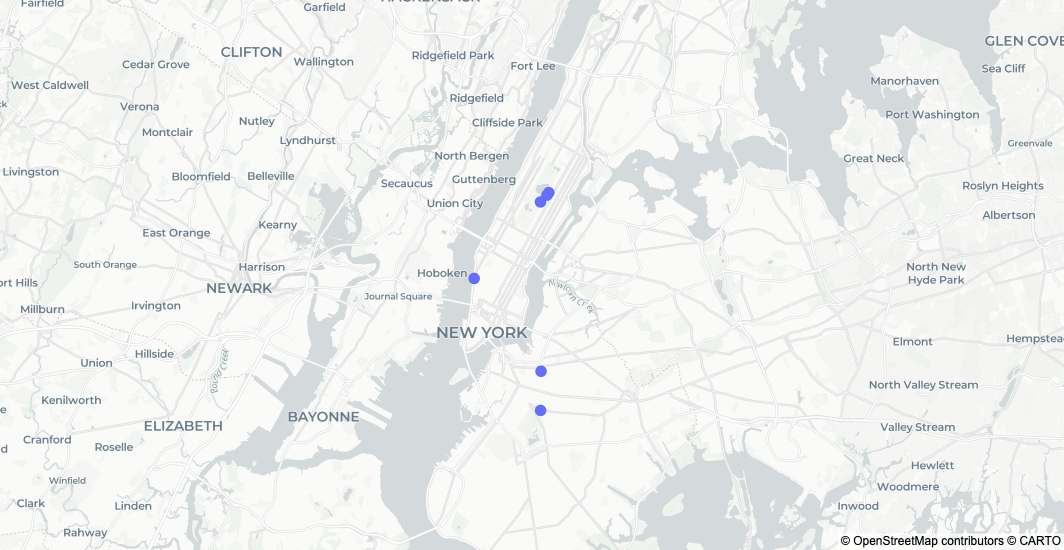

In [18]:
# the center of the map: the average latitude and the average longitude of our places
center = {"lat": table["lat"].mean(), "lon": table["lon"].mean()}

fig = px.scatter_map(
    table,
    lat="lat",                           # the columns with each place's coordinates
    lon="lon",
    hover_name="name",
    hover_data={"address": True, "lat": False, "lon": False},
    center=center,                       # where the map is centered at first
    zoom=10,                             # how far in: a bigger number is closer
    height=550,
)

fig.update_traces(marker={"size": 12})
fig.update_layout(map_style="carto-positron", margin={"l": 0, "r": 0, "t": 0, "b": 0})

fig.show()

## 5. Save the results (so we don't ask twice)

Geocoding the same places every time we run the notebook would break the usage policy's spirit. So we save the results as a CSV, and read the file back next time.

In [19]:
table.to_csv("geocoded_places.csv", index=False)

pd.read_csv("geocoded_places.csv").head()

,query,name,address,type,lat,lon
0,"Pratt Institute, Brooklyn",Pratt Institute,"Pratt Institute, 200, Willoughby Avenue, Clint...",university,40.691338,-73.963016
1,Brooklyn Museum,Brooklyn Museum,"Brooklyn Museum, 200, Eastern Parkway, Brookly...",museum,40.670955,-73.963295
2,"Metropolitan Museum of Art, New York",The Metropolitan Museum of Art,"The Metropolitan Museum of Art, 1000, 5th Aven...",museum,40.779440,-73.963382
3,"Cooper Hewitt, New York","Cooper–Hewitt, Smithsonian Design Museum","Cooper–Hewitt, Smithsonian Design Museum, 2, E...",museum,40.784284,-73.957699
4,"Guggenheim Museum, New York",Guggenheim Museum,"Guggenheim Museum, 1071, 5th Avenue, Carnegie ...",museum,40.782993,-73.958925


## 6. Going the other way: reverse geocoding

**Reverse geocoding** turns coordinates into an address. The address is `/reverse`, and the parameters are `lat` and `lon`.

In [20]:
reverse_params = {"lat": 40.6913, "lon": -73.9630, "format": "jsonv2"}

response = requests.get("https://nominatim.openstreetmap.org/reverse", params=reverse_params, headers=headers)

print(response.json()["display_name"])

200, Willoughby Avenue, Clinton Hill, Brooklyn, Kings County, New York, 11205, United States


## Things to try

* **Be specific.** Names can be ambiguous. Try `geocode("30 Lincoln Center Plaza")`: with no city, it matches a shopping center in Worcester, Massachusetts. Look at `address` to see where a match landed, and add a city or state to the query to fix it.
* **Wording matters.** `geocode("Cooper Hewitt, Smithsonian Design Museum")` finds nothing, but `geocode("Cooper Hewitt, New York")` works. When there's no match, try a shorter or simpler version of the name.
* **More than one result.** Change `"limit": 1` to `5` and look at all of the matches. How would you decide which one to keep?
* **Fewer, better matches.** Add `"countrycodes": "us"` to the parameters, to search only the U.S. Add `"addressdetails": 1` to get the address as separate pieces (`road`, `city`, `postcode`) in the result.
* **Structured search.** Instead of `q`, use separate parameters: `street`, `city`, `state`, `postalcode`. Try `{"street": "200 Willoughby Avenue", "city": "Brooklyn", "state": "New York", "format": "jsonv2"}`.
* **Your own data.** Geocode the place names in a dataset you already have, like the museums in a CSV from this course. Which ones couldn't be found, and why?
* **An empty map?** If a map shows no dots, check the `center` and `zoom`. Coordinates near (0, 0) mean something went wrong: latitude and longitude may be swapped, or missing values (`NaN`) may have been averaged in.
* **Back to Week 10.** Use the coordinates with a pydeck `ColumnLayer` to draw a bar at each place.

## Cautions

* **Free doesn't mean unlimited.** For hundreds of places, wait between requests and cache the results. For thousands, use a different approach, like downloading OSM data or paying for a geocoding service.
* **Matches are guesses.** Always look at `display_name` to see what was actually matched, and check a few on a map.
* **The data is crowd-sourced.** OSM is edited by volunteers: it can be very detailed in one neighborhood and thin in another.